In [1]:
import os
REPO = "India-Demand-Forecasting-ML"
BRANCH = "feature/cleaning-weather-eda"
if not os.path.exists(REPO):
    !git clone -b {BRANCH} https://github.com/tanishmaity03/India-Demand-Forecasting-ML.git
%cd {REPO}

import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
for p in ["results/figures", "results/tables", "data/processed"]:
    Path(p).mkdir(parents=True, exist_ok=True)

Cloning into 'India-Demand-Forecasting-ML'...
remote: Enumerating objects: 60, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (46/46), done.
remote: Total 60 (delta 12), reused 53 (delta 8), pack-reused 0 (from 0)
Receiving objects: 100% (60/60), 15.04 MiB | 17.38 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/India-Demand-Forecasting-ML


In [3]:
REGIONS = ["northern", "western", "eastern", "southern", "north_eastern"]
india = pd.read_excel("data/raw/india_hourly_demand.xlsx")
india.columns = ["datetime", "national"] + REGIONS
india["datetime"] = pd.to_datetime(india["datetime"])
india = india.sort_values("datetime").reset_index(drop=True)

wx = pd.read_csv("data/raw/india_weather_hourly.csv", parse_dates=["datetime"])
print(india.shape, wx.shape)
print(wx.groupby("region").size())

(46728, 7) (233640, 9)
region
eastern          46728
north_eastern    46728
northern         46728
southern         46728
western          46728
dtype: int64


In [4]:
WX_RAW = ["temperature_2m", "relative_humidity_2m", "dewpoint_2m", "wind_speed_10m",
          "shortwave_radiation", "precipitation"]
wx_audit = wx.groupby("region").agg(city=("city", "first"), rows=("datetime", "size"),
                                    start=("datetime", "min"), end=("datetime", "max"),
                                    duplicate_ts=("datetime", lambda d: int(d.duplicated().sum())))
wx_audit["missing_values"] = wx.groupby("region")[WX_RAW].apply(lambda g: int(g.isna().sum().sum()))
print(wx_audit)
wx[WX_RAW].describe().T.round(2)

                   city   rows      start                 end  duplicate_ts  missing_values
region                                                                                     
eastern         Kolkata  46728 2019-01-01 2024-04-30 23:00:00             0               0
north_eastern  Guwahati  46728 2019-01-01 2024-04-30 23:00:00             0               0
northern          Delhi  46728 2019-01-01 2024-04-30 23:00:00             0               0
southern        Chennai  46728 2019-01-01 2024-04-30 23:00:00             0               0
western          Mumbai  46728 2019-01-01 2024-04-30 23:00:00             0               0


,count,mean,std,min,25%,50%,75%,max
temperature_2m,233640.0,25.62,5.60,2.0,23.00,26.50,29.00,45.40
relative_humidity_2m,233640.0,73.85,18.77,7.0,62.00,78.00,89.00,100.00
dewpoint_2m,233640.0,19.90,5.81,-5.4,15.70,21.90,24.70,29.80
wind_speed_10m,233640.0,2.73,1.51,0.0,1.61,2.41,3.63,19.14
shortwave_radiation,233640.0,204.32,277.73,0.0,0.00,9.00,402.00,1013.00
precipitation,233640.0,0.19,0.88,0.0,0.00,0.00,0.00,47.60


In [5]:
w = india.loc[india["datetime"].dt.year == 2019, REGIONS].mean()
w = (w / w.sum()).round(4)
print("Demand weights (2019 shares):"); print(w)

wide = wx.pivot(index="datetime", columns="region", values=WX_RAW)
wide = wide.interpolate(method="time", limit=3)          # fill tiny gaps only

RENAME = {"temperature_2m": "temp_c", "relative_humidity_2m": "rh_pct", "dewpoint_2m": "dewpoint_c",
          "wind_speed_10m": "wind_ms", "shortwave_radiation": "solar_wm2", "precipitation": "precip_mm"}
nat = pd.DataFrame({RENAME[v]: sum(wide[v][r] * w[r] for r in REGIONS) for v in WX_RAW})
for r in REGIONS:
    nat[f"temp_{r}"] = wide["temperature_2m"][r]         # keep regional temperatures
nat = nat.reset_index()
nat.head()

Demand weights (2019 shares):
northern         0.3019
western          0.3098
eastern          0.1141
southern         0.2616
north_eastern    0.0126
dtype: float64


,datetime,temp_c,rh_pct,dewpoint_c,wind_ms,solar_wm2,precip_mm,temp_northern,temp_western,temp_eastern,temp_southern,temp_north_eastern
0,2019-01-01 00:00:00,15.47688,74.1325,10.66905,2.801835,0.0,0.0,8.8,17.3,13.0,22.3,11.4
1,2019-01-01 01:00:00,15.34361,73.9827,10.46924,2.565504,0.0,0.0,8.1,18.0,12.8,21.9,10.5
2,2019-01-01 02:00:00,15.12250,74.6729,10.35216,2.359264,0.0,0.0,7.6,18.2,12.2,21.7,9.6
3,2019-01-01 03:00:00,14.41399,78.2276,10.53209,2.237842,0.0,0.0,7.3,16.7,11.6,21.4,9.1
4,2019-01-01 04:00:00,13.89130,80.6348,10.44438,2.196258,0.0,0.0,7.1,15.4,11.1,21.4,8.9


In [6]:
df = india.merge(nat, on="datetime", how="left", validate="one_to_one")
print("rows:", len(df), "| rows lacking weather:", int(df["temp_c"].isna().sum()))

rows: 46728 | rows lacking weather: 0


In [7]:
def neighbour_dev_pct(series, days=(-3, -2, -1, 1, 2, 3)):
    """% deviation from the median of the same hour on neighbouring days."""
    ref = pd.concat([series.shift(24 * k) for k in days], axis=1).median(axis=1)
    return (series - ref) / ref * 100

s = df.set_index("datetime")["national"]
df["demand_dev_pct"] = neighbour_dev_pct(s).values
df["anomaly_flag"] = (df["demand_dev_pct"].abs() > 15).astype(int)

flagged = df.loc[df["anomaly_flag"] == 1, ["datetime", "national", "demand_dev_pct"]].copy()
flagged[["national", "demand_dev_pct"]] = flagged[["national", "demand_dev_pct"]].round(1)
flagged.to_csv("results/tables/flagged_demand_anomalies.csv", index=False)
print("Flagged hours:", len(flagged))
print(flagged.groupby(flagged["datetime"].dt.date).size().sort_values(ascending=False).head(10))

Flagged hours: 20
datetime
2022-08-15    4
2024-04-25    3
2024-03-25    3
2020-01-20    2
2020-11-15    2
2021-08-22    2
2021-11-17    2
2020-03-22    1
2021-12-17    1
dtype: int64


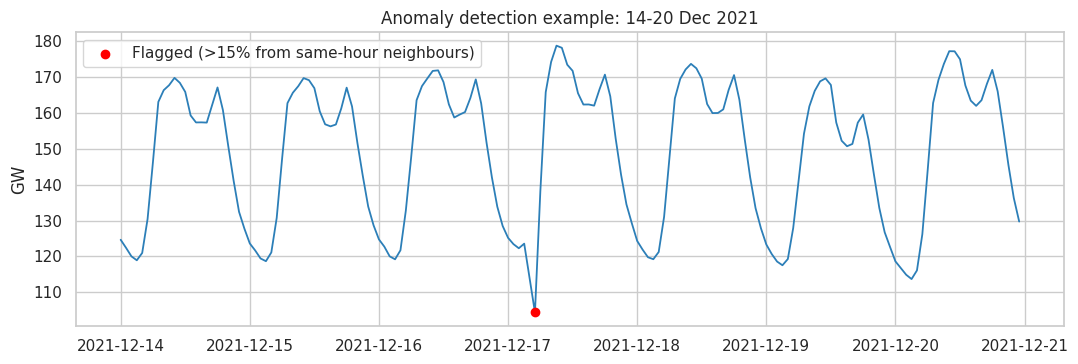

In [8]:
win = df[(df["datetime"] >= "2021-12-14") & (df["datetime"] < "2021-12-21")]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(win["datetime"], win["national"] / 1000, color="#2c7fb8", lw=1.3)
fl = win[win["anomaly_flag"] == 1]
ax.scatter(fl["datetime"], fl["national"] / 1000, color="red", zorder=3,
           label="Flagged (>15% from same-hour neighbours)")
ax.set_ylabel("GW"); ax.set_title("Anomaly detection example: 14-20 Dec 2021"); ax.legend()
plt.tight_layout()
plt.savefig("results/figures/02_anomaly_example.png", dpi=150)
plt.show()

In [9]:
load = pd.read_csv("data/raw/load_dataset.csv")
load.columns = [c.strip().lower().replace(" ", "_") for c in load.columns]
load["datetime"] = pd.to_datetime(dict(year=load["year"], month=load["mo"], day=load["dy"], hour=load["hr"]))
load = load.drop(columns=["year", "mo", "dy", "hr"]).set_index("datetime")

# a) irradiance sentinel -999 -> NaN -> average of same hour on the previous and next day
n_sentinel = int((load["irradiance"] == -999).sum())
load.loc[load["irradiance"] == -999, "irradiance"] = np.nan
fill = (load["irradiance"].shift(24) + load["irradiance"].shift(-24)) / 2
load["irradiance"] = load["irradiance"].fillna(fill)

# b) non-positive load = meter drop-out -> NaN -> time interpolation (runs are <= 8 h)
n_nonpos = int((load["electric_load"] <= 0).sum())
load.loc[load["electric_load"] <= 0, "electric_load"] = np.nan
load["electric_load"] = load["electric_load"].interpolate(method="time", limit=8, limit_direction="both")

# c) flag (do not remove) extreme load spikes
load["spike_flag"] = (neighbour_dev_pct(load["electric_load"]).abs() > 50).astype(int)

print("irradiance NaN left:", int(load["irradiance"].isna().sum()),
      "| load NaN left:", int(load["electric_load"].isna().sum()))
print("load spike-flagged hours:", int(load["spike_flag"].sum()))

irradiance NaN left: 0 | load NaN left: 0
load spike-flagged hours: 72


In [10]:
df.to_csv("data/processed/india_demand_weather.csv", index=False)
load.reset_index().to_csv("data/processed/load_dataset_clean.csv", index=False)

report = pd.DataFrame([
    ["India demand", "Missing / duplicate timestamps", 0, "None needed"],
    ["India demand", "Hours flagged as anomalous (>15% from same-hour neighbours)", int(df["anomaly_flag"].sum()),
     "Flagged, kept (holidays, curfews and events are real demand)"],
    ["India weather", "Missing values", int(wx[WX_RAW].isna().sum().sum()), "Interpolated up to 3 h"],
    ["India + weather", "Rows lacking weather after merge", int(df["temp_c"].isna().sum()), "None needed"],
    ["load_dataset", "Irradiance sentinel values (-999)", n_sentinel, "Set to NaN, filled with mean of same hour +-24 h"],
    ["load_dataset", "Non-positive load readings", n_nonpos, "Treated as meter drop-outs; time-interpolated (runs <= 8 h)"],
    ["load_dataset", "Hours flagged as load spikes (>50% from neighbours)", int(load["spike_flag"].sum()), "Flagged, kept"],
], columns=["dataset", "issue", "count", "action"])
report.to_csv("results/tables/cleaning_report.csv", index=False)
report

,dataset,issue,count,action
0,India demand,Missing / duplicate timestamps,0,None needed
1,India demand,Hours flagged as anomalous (>15% from same-hou...,20,"Flagged, kept (holidays, curfews and events ar..."
2,India weather,Missing values,0,Interpolated up to 3 h
3,India + weather,Rows lacking weather after merge,0,None needed
4,load_dataset,Irradiance sentinel values (-999),24,"Set to NaN, filled with mean of same hour +-24 h"
5,load_dataset,Non-positive load readings,79,Treated as meter drop-outs; time-interpolated ...
6,load_dataset,Hours flagged as load spikes (>50% from neighb...,72,"Flagged, kept"


In [11]:
!zip -qr /content/day2_outputs.zip data/processed results
from google.colab import files
files.download("/content/day2_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>